## 5.3 전이 학습 

일반적으로 합성곱 신경망 기반의 딥러닝 모델을 제대로 훈련시키려면 많은 양의 데이터가 필요하다. 이를 해결하기 위한 것이 전이학습(transfer learning)이다. 
- 이미지넷처럼 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 과제에 맞게 보정해서 사용하는 것을 의미 

### 5.3.1 특성 추출 기법
특성 추출 (feature extractor)은 imagenet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막 완전연결층 부분만 새로 만든다. 

이미지 분류를 위해 두 부분으로 구성된다. 
- 합성곱층 : 합성곱층과 풀링층으로 구성 
- 데이터 분류기 (완전연걸층) : 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분 

In [1]:
pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 44.1 MB/s  0:00:01 eta 0:00:01

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import copy
import glob
import cv2
import shutil


import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader


import matplotlib.pyplot as plt

In [4]:
data_path = '/Users/seomichelle/26-2 ESAA:Python/dataset/dogs-vs-cats'


transform = transforms.Compose(
            [
                transforms.Resize([256, 256]),
                transforms.RandomResizedCrop(224),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor()
])
train_dataset = torchvision.datasets.ImageFolder(
                        data_path,


                        transform=transform
    )
train_loader = torch.utils.data.DataLoader(
                        train_dataset,
                        batch_size=32,
                        num_workers=8,
                        shuffle=True
    )


print(len(train_dataset))

37500


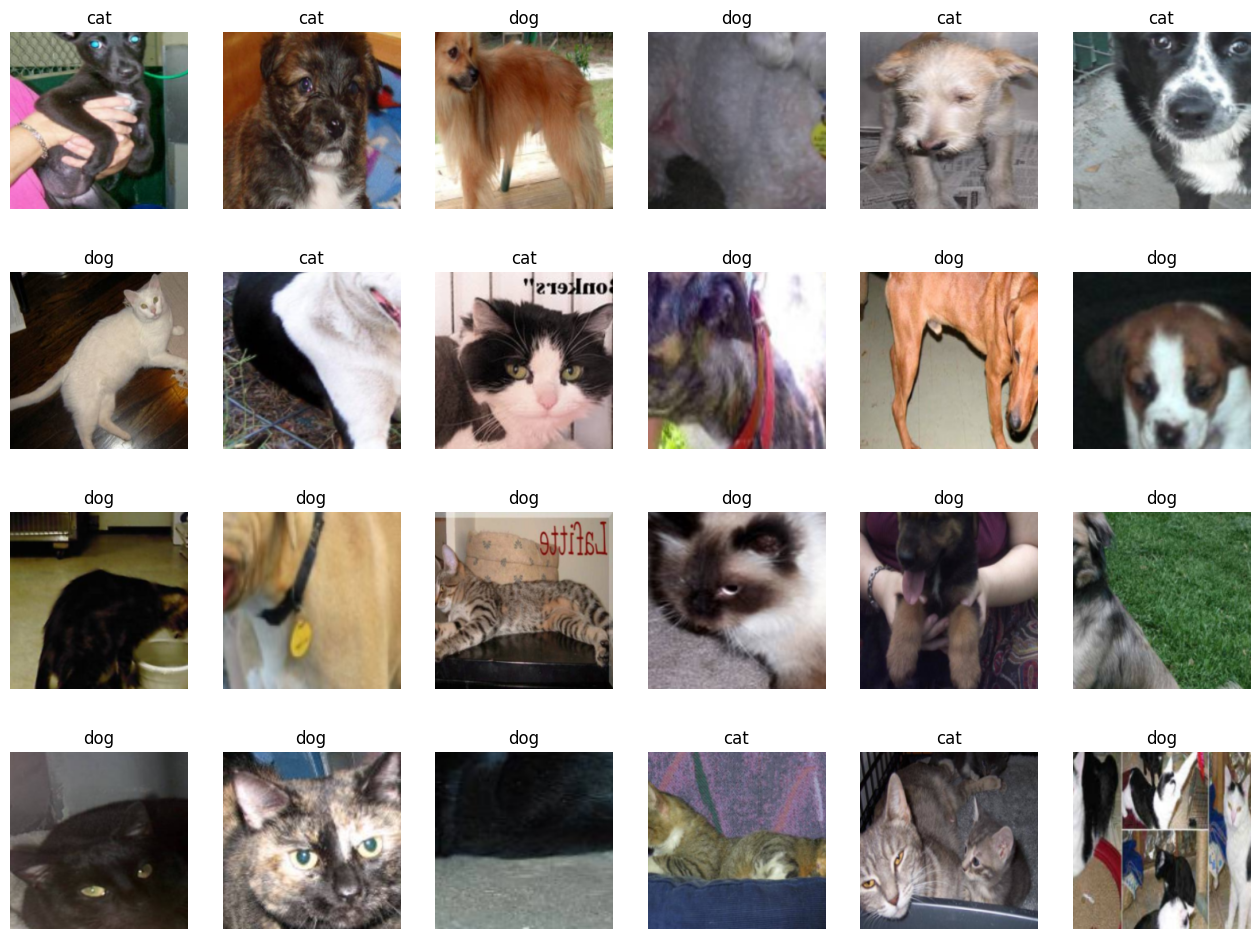

In [6]:
import numpy as np
samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'}
fig = plt.figure(figsize=(16,24))
for i in range(24):
    a = fig.add_subplot(4,6,i+1)
    a.set_title(classes[labels[i].item()])
    a.axis('off')
    a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

In [7]:
resnet18 = models.resnet18(pretrained=True)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/seomichelle/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 43.8MB/s]


In [8]:
def set_parameter_requires_grad(model, feature_extracting=True):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False


set_parameter_requires_grad(resnet18)

In [9]:
resnet18.fc = nn.Linear(512, 2)


In [10]:
for name, param in resnet18.named_parameters():
    if param.requires_grad:
        print(name, param.data)

fc.weight tensor([[-0.0205, -0.0348,  0.0435,  ...,  0.0307, -0.0392,  0.0219],
        [-0.0352, -0.0405, -0.0329,  ..., -0.0378,  0.0137,  0.0003]])
fc.bias tensor([-0.0135, -0.0362])


In [11]:
model = models.resnet18(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [15]:
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13,
                is_train=True):
    since = time.time()
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs-1))
        print('-' * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
        epoch_loss = running_loss / len(dataloaders.dataset)
        epoch_acc = running_corrects.double() / len(dataloaders.dataset)

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())


        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('/Users/seomichelle/26-2 ESAA:Python/dataset/dogs-vs-cats/',
                    '{0:0=2d}.pth'.format(epoch)))

        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
                                                        time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history

In [16]:
params_to_update = []
for name, param in resnet18.named_parameters():
    if param.requires_grad == True:
        params_to_update.append(param)
        print("\t", name)

optimizer = optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion,
                                              optimizer, device)

Epoch 0/12
----------
Loss: 0.6548 Acc: 0.6498

Epoch 1/12
----------
Loss: 0.6538 Acc: 0.6525

Epoch 2/12
----------
Loss: 0.6576 Acc: 0.6462

Epoch 3/12
----------
Loss: 0.6528 Acc: 0.6541

Epoch 4/12
----------
Loss: 0.6563 Acc: 0.6489

Epoch 5/12
----------
Loss: 0.6542 Acc: 0.6538

Epoch 6/12
----------
Loss: 0.6563 Acc: 0.6497

Epoch 7/12
----------
Loss: 0.6572 Acc: 0.6473

Epoch 8/12
----------
Loss: 0.6574 Acc: 0.6472

Epoch 9/12
----------
Loss: 0.6560 Acc: 0.6480

Epoch 10/12
----------
Loss: 0.6518 Acc: 0.6535

Epoch 11/12
----------
Loss: 0.6550 Acc: 0.6495

Epoch 12/12
----------
Loss: 0.6555 Acc: 0.6469

Training complete in 169m 47s
Best Acc: 0.654053


In [19]:
test_path = '/Users/seomichelle/26-2 ESAA:Python/dataset/dogs-vs-cats'

transform = transforms.Compose(
            [
                transforms.Resize(224),
                transforms.CenterCrop(224),
                transforms.ToTensor(),
])
test_dataset = torchvision.datasets.ImageFolder(
        root=test_path,
        transform=transform
)
test_loader = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=32,
        num_workers=1,
        shuffle=True
)

print(len(test_dataset))

37500


In [20]:
def eval_model(model, dataloaders, device):
    since = time.time()
    acc_history = []
    best_acc = 0.0

    saved_models = glob.glob('../chap05/data/catanddog/' + '*.pth')
    saved_models.sort()
    print('saved_model', saved_models)

    for model_path in saved_models:
        print('Loading model', model_path)

        model.load_state_dict(torch.load(model_path))
        model.eval()
        model.to(device)
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.no_grad():
                outputs = model(inputs)

            _, preds = torch.max(outputs.data, 1)
            preds[preds >= 0.5] = 1
            preds[preds < 0.5] = 0
            running_corrects += preds.eq(labels.cpu()).int().sum()

        epoch_acc = running_corrects.double() / len(dataloaders.dataset)
        print('Acc: {:.4f}'.format(epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        print()

    time_elapsed = time.time() - since
    print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
                                                          time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))

    return acc_history

In [21]:
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model []
Validation complete in 0m 0s
Best Acc: 0.000000


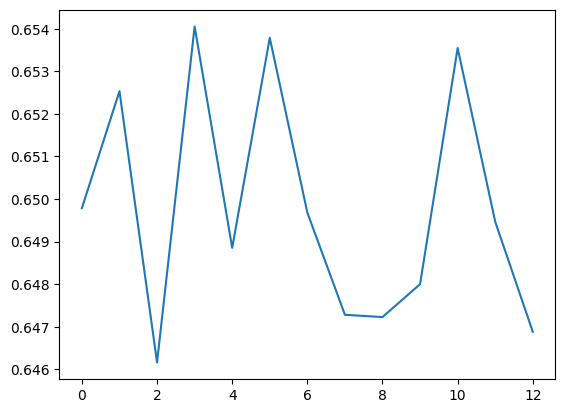

In [22]:
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

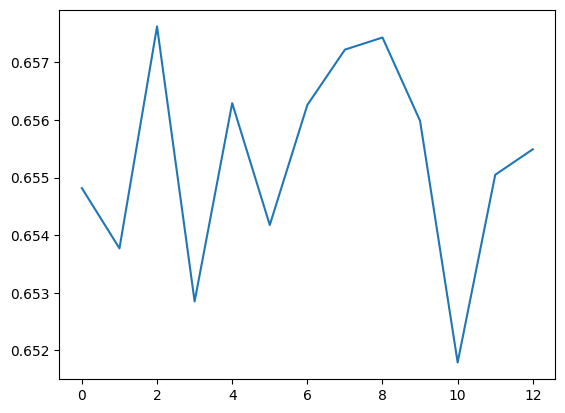

In [23]:
plt.plot(train_loss_hist)
plt.show()